In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
from PIL import Image

# Path to your dataset folder
dataset_path = "/content/drive/MyDrive/Mango Leaf Dataset/Raw Data"

# Loop over each class folder
for class_name in os.listdir(dataset_path):
    class_folder = os.path.join(dataset_path, class_name)
    if os.path.isdir(class_folder):
        # List all image files in the folder
        images = [f for f in os.listdir(class_folder) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
        images.sort()  # Optional: sort files alphabetically

        # Rename each image and save as JPG
        for idx, img_name in enumerate(images, start=1):
            img_path = os.path.join(class_folder, img_name)
            new_name = f"{class_name}_{idx:03d}.jpg"  # Ensure JPG extension
            new_path = os.path.join(class_folder, new_name)

            # Open image and save as JPG (converts PNG to JPG if needed)
            with Image.open(img_path) as img:
                rgb_img = img.convert('RGB')  # Convert to RGB if PNG
                rgb_img.save(new_path, "JPEG", quality=95)  # High quality

            # Remove old file if different from new
            if img_path != new_path:
                os.remove(img_path)

print("All images renamed and saved as JPG successfully!")


All images renamed and saved as JPG successfully!


In [ ]:
import os
total_images = 0
print("Number of images per class:\n")

# Loop over each class folder
for class_name in os.listdir(dataset_path):
    class_folder = os.path.join(dataset_path, class_name)
    if os.path.isdir(class_folder):
        # Count images in this class folder
        image_count = len([f for f in os.listdir(class_folder) if f.lower().endswith(('.jpg', '.jpeg', '.png'))])
        total_images += image_count
        print(f"{class_name}: {image_count} images")

print("\nTotal dataset size:", total_images, "images")


Number of images per class:

Amrupali: 308 images
Banana: 351 images
Brunei King: 300 images
Harivanga: 366 images
Surjapuri: 370 images
Kacha Mitha: 376 images
Himsagor: 341 images
Bandigori: 332 images

Total dataset size: 2744 images


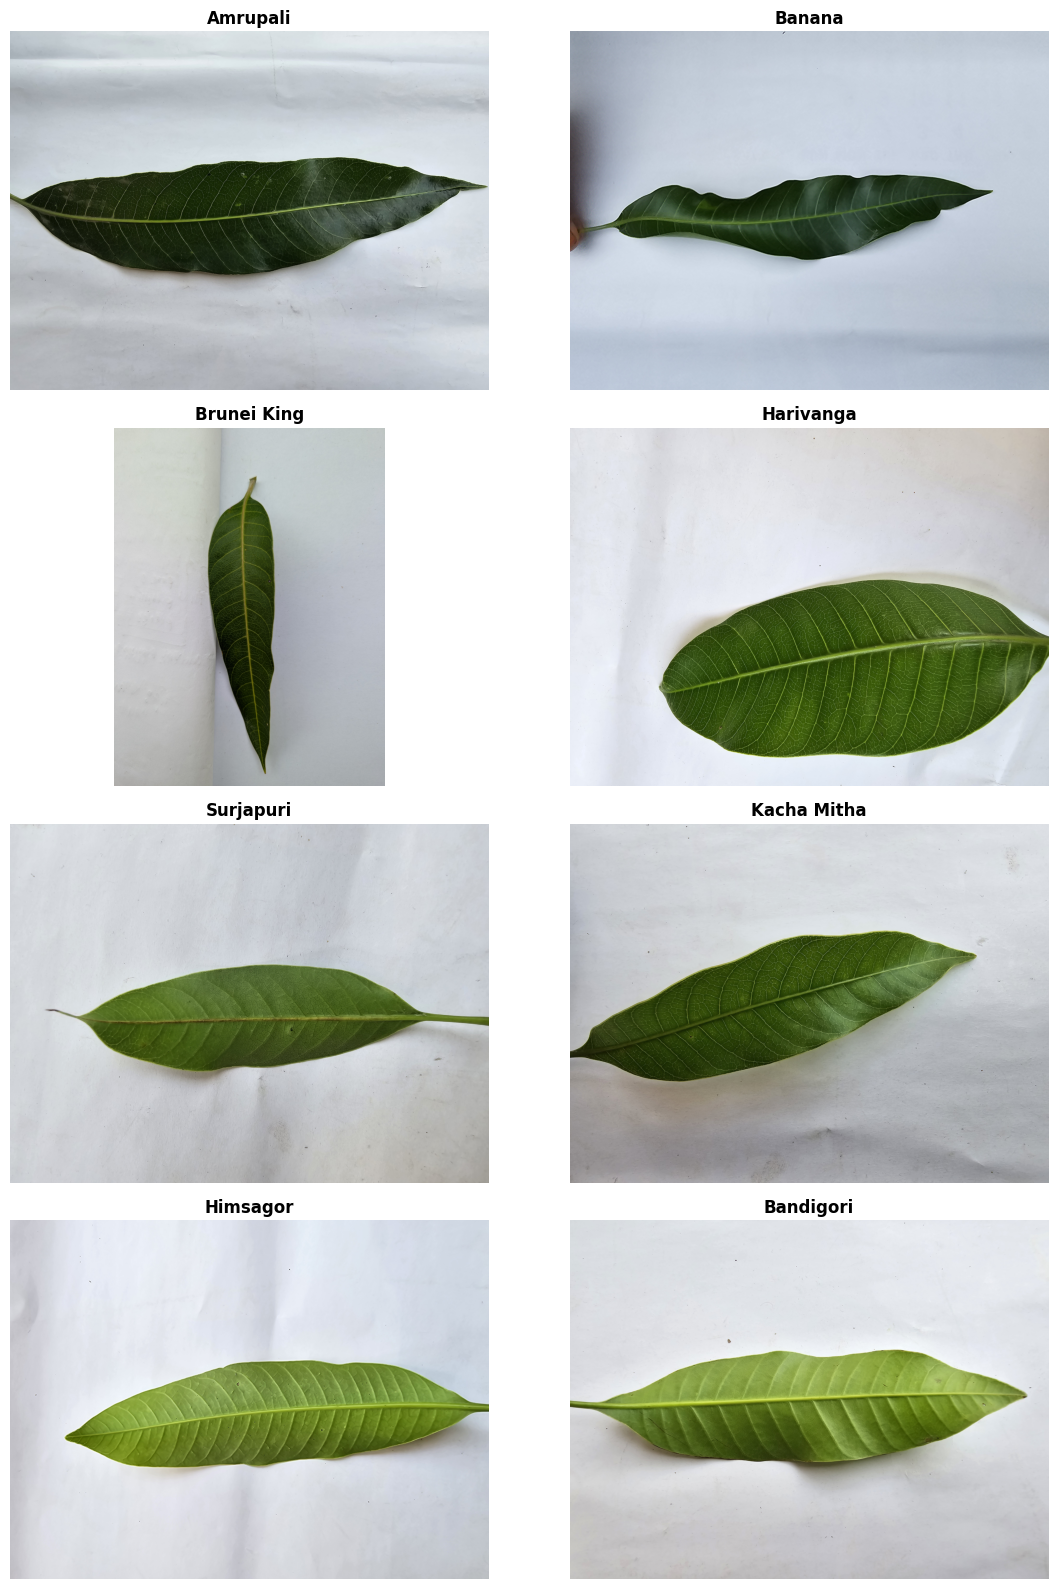

Professional preview image saved at: /content/drive/MyDrive/Mango Leaf Dataset/mango_leaf_preview.png


In [ ]:
import os
import random
from PIL import Image
import matplotlib.pyplot as plt


# Path to save the preview figure
save_path = "/content/drive/MyDrive/Mango Leaf Dataset/mango_leaf_preview.png"

# Collect one random image per class
class_images = []

for class_name in os.listdir(dataset_path):
    class_folder = os.path.join(dataset_path, class_name)
    if os.path.isdir(class_folder):
        images = [f for f in os.listdir(class_folder) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
        if images:
            img_name = random.choice(images)
            img_path = os.path.join(class_folder, img_name)
            class_images.append((class_name, img_path))

# Plot images in 4x2 grid using original sizes
rows, cols = 4, 2
fig, axes = plt.subplots(rows, cols, figsize=(12, 16))  # Adjust figure size as needed

for i, (class_name, img_path) in enumerate(class_images):
    row = i // cols
    col = i % cols
    img = Image.open(img_path)  # Use original size
    axes[row, col].imshow(img)
    axes[row, col].set_title(class_name, fontsize=12, fontweight='bold')  # Small bold class name
    axes[row, col].axis('off')

# Hide unused subplots if any
for j in range(len(class_images), rows*cols):
    row = j // cols
    col = j % cols
    axes[row, col].axis('off')

plt.tight_layout()
fig.savefig(save_path, format='png', dpi=300)  # Save high-quality PNG
plt.show()

print(f"Professional preview image saved at: {save_path}")
